# CSI5341 Assignment3
Lingjia Liu

### data preparation

load images, labels, and corresponding bounding box information.

resize images to 64 * 64, normalize width height of the bounding box for each images.

In [1]:
import numpy as np
import os
import json
import pandas as pd
from skimage import io, transform
from keras.preprocessing.image import load_img
from tensorflow.keras import utils

resize=64
LearnRate=0.001
file_dir = "a3_dataset/img"
with open('a3_dataset/bbox.json', 'r') as bbox_file:
    bbox_data = json.load(bbox_file)
    
data = pd.DataFrame(columns=['label', 'image', 'bbox'])
for class_name, class_data in bbox_data.items():
    #norm_bbox_data[class_name] = {}
    for img_name, bbox_info in class_data.items():
        # Load the image corresponding to this bounding box
        img_path = os.path.join(file_dir, class_name, img_name + '.png')
        
        # load image
        img = io.imread(img_path)
        height = bbox_info['height'] / (img.shape[0] )  # Normalize height
        width = bbox_info['width'] / (img.shape[1]) # Normalize width
        
        #resize to 64 x 64:
        img_resized = transform.resize(img, (resize,resize), mode='reflect', anti_aliasing=True) #
        
        # label height width to imgframe
        data = data.append({'label': class_name, 'image': img_resized, 'bbox': {'height': height, 'width': width}}, ignore_index=True)
        
print('total length of Sample list', len(data))


total length of Sample list 1000


In [2]:
print(f'Data size: {data.shape[0]} x {resize}, label size {data.label.shape[0]}')
print("Image shape: ", data.image[0].shape)
print("\nshow the structure of data:\n")
print(data.head())

Data size: 1000 x 64, label size 1000
Image shape:  (64, 64, 3)

show the structure of data:

              label                                              image  \
0  Common_Chickweed  [[[0.3655908986976762, 0.2942424117502789, 0.2...   
1  Common_Chickweed  [[[0.49384377181444916, 0.4699781220692633, 0....   
2  Common_Chickweed  [[[0.36824951171875, 0.3020424038756127, 0.248...   
3  Common_Chickweed  [[[0.4185779424478749, 0.3310909292225195, 0.2...   
4  Common_Chickweed  [[[0.2924827953083705, 0.22547929340220402, 0....   

                                                bbox  
0  {'height': 0.9661733615221987, 'width': 0.9006...  
1  {'height': 0.9313304721030042, 'width': 0.3776...  
2  {'height': 0.7974683544303798, 'width': 0.5063...  
3  {'height': 0.8446601941747572, 'width': 0.5922...  
4  {'height': 0.9672131147540983, 'width': 0.4856...  


shuffle and split data, 750 images for training, 125 for validation and 125 for testing

In [3]:
from sklearn.model_selection import train_test_split

# Shuffle data
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

#split data
data_train, data_val = train_test_split(data, test_size=0.25, stratify=data.label, random_state=42)
data_val, data_test = train_test_split(data_val, test_size=0.5, stratify=data_val.label, random_state=42)


In [4]:
print(f'{data_train.shape[0]} training samples')
print(f'{data_val.shape[0]} validation samples')
print(f'{data_test.shape[0]} testing samples')

750 training samples
125 validation samples
125 testing samples


## 3.1 Network based on VGG-16

Convert the labels to one-hot vectors for data

In [5]:
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

def one_hot_Label(data):
    label_encoder = LabelEncoder()
    label_oh = to_categorical(label_encoder.fit_transform(data.label),num_classes=4)
    return label_oh

train_label_oh = one_hot_Label(data_train)
val_label_oh = one_hot_Label(data_val)
test_label_oh = one_hot_Label(data_test)

In [6]:
print(train_label_oh)

[[0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 ...
 [0. 0. 1. 0.]
 [0. 1. 0. 0.]
 [0. 0. 0. 1.]]


extract data for each image into a numpy array

In [7]:
train_x = np.stack(data_train.image)
val_x = np.stack(data_val.image)
test_x = np.stack(data_test.image)

### Create CNN

In [8]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten,Conv2D,MaxPooling2D

# Load the VGG-16 model with pre-trained weights
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(64,64, 3))

#set non-trainable
for layer in base_model.layers:
    layer.trainable = False

# Using the first two blocks 
x = base_model.layers[6].output
x = Conv2D(64,(3,3), activation='relu')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Flatten()(x)
output_clf = Dense(4, activation='softmax')(x)

vgg_model_clf = Model(inputs=base_model.input, outputs=output_clf)


2023-10-31 10:32:14.504802: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2023-10-31 10:32:14.504822: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2023-10-31 10:32:14.504827: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2023-10-31 10:32:14.504854: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2023-10-31 10:32:14.504868: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [9]:
print(vgg_model_clf.summary())

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 64, 64, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 64, 64, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 32, 32, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 32, 32, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 32, 32, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 16, 16, 128)       0     

In [10]:
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

adam = tf.keras.optimizers.legacy.Adam(learning_rate = LearnRate) 
vgg_model_clf.compile(optimizer=adam, loss='categorical_crossentropy', metrics=['accuracy'])

batchSize = 32
nEpochs = 25

# Train the model
history_vggCLF = vgg_model_clf.fit(train_x, train_label_oh, 
                    batch_size=batchSize, 
                    epochs=nEpochs,  
                    validation_data=(val_x, val_label_oh),
                    verbose=1) 

Epoch 1/25


2023-10-31 10:32:16.350113: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


24/24 [==============================] - 5s 128ms/step - loss: 6.3568 - accuracy: 0.2760 - val_loss: 1.4411 - val_accuracy: 0.2640
Epoch 2/25
24/24 [==============================] - 1s 49ms/step - loss: 1.3679 - accuracy: 0.3160 - val_loss: 1.4018 - val_accuracy: 0.2320
Epoch 3/25
24/24 [==============================] - 1s 48ms/step - loss: 1.3338 - accuracy: 0.3680 - val_loss: 1.4098 - val_accuracy: 0.2400
Epoch 4/25
24/24 [==============================] - 1s 50ms/step - loss: 1.2594 - accuracy: 0.4200 - val_loss: 1.3351 - val_accuracy: 0.3840
Epoch 5/25
24/24 [==============================] - 1s 49ms/step - loss: 1.1688 - accuracy: 0.4933 - val_loss: 1.3309 - val_accuracy: 0.4000
Epoch 6/25
24/24 [==============================] - 1s 49ms/step - loss: 1.0540 - accuracy: 0.5467 - val_loss: 1.2802 - val_accuracy: 0.4400
Epoch 7/25
24/24 [==============================] - 1s 48ms/step - loss: 0.9498 - accuracy: 0.6013 - val_loss: 1.1435 - val_accuracy: 0.5040
Epoch 8/25
24/24 [=====

Evaluate the model on the validation and test set

In [11]:
# Evaluate the model on the validation and test set
loss_val, acc_val = vgg_model_clf.evaluate(val_x,val_label_oh)
print(f'Validation Loss: {loss_val:.4f}, Validation Accuracy: {acc_val:.4f}')
loss_test, acc_test = vgg_model_clf.evaluate(test_x,test_label_oh)
print(f'Test Loss: {loss_test:.4f}, test Accuracy: {acc_test:.4f}')

4/4 [==============================] - 0s 42ms/step - loss: 0.8249 - accuracy: 0.7360
Validation Loss: 0.8249, Validation Accuracy: 0.7360
4/4 [==============================] - 0s 41ms/step - loss: 0.7725 - accuracy: 0.7200
Test Loss: 0.7725, test Accuracy: 0.7200


In [12]:
import matplotlib.pyplot as plt


def plot_loss(epochs, history):
    
    #epochs_list = range(1,  epochs + 1)
    train_loss = history.history['loss']
    val_loss = history.history['val_loss']
    max_loss = max(max(train_loss), max(val_loss))
    norm_train_loss = [x / max_loss for x in train_loss]
    norm_val_loss = [x / max_loss for x in val_loss]
    
    # loss curves
    plt.plot( norm_train_loss)
    plt.plot( norm_val_loss)
    plt.title('Loss on Training and Validation set')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(['Training Loss','Validation Loss'])
    
def plot_acc(epochs, history):
    # accuracy curves
    
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Accuracy on Training and Validation set')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(['Training Accuracy','Validation Accuracy'])

    # Show the plots
    plt.tight_layout()
    plt.show()

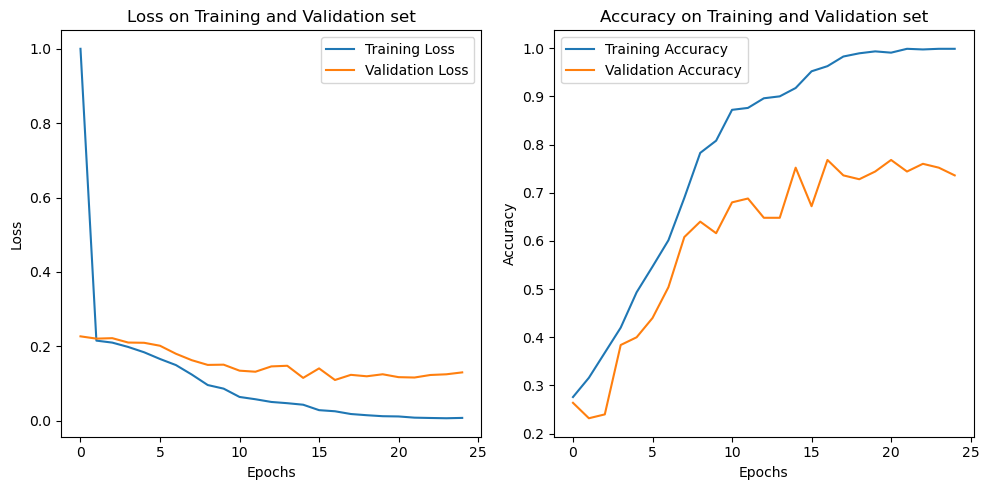

In [13]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plot_loss(nEpochs,history_vggCLF)
plt.subplot(1, 2, 2)
plot_acc(nEpochs,history_vggCLF)

In [14]:
from sklearn.metrics import confusion_matrix

class_names = data.label.unique() #class labels (category names)
def plot_conf_mx(y,y_pred):
    cm = confusion_matrix(np.argmax(y, axis=-1), np.argmax(y_pred, axis=-1))
    print(cm)

    # Plot the confusion matrix
    plt.figure(figsize=(4,4))
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Oranges)
    plt.colorbar()
    
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)

    # Display the matrix values as text
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, str(cm[i, j]), horizontalalignment="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()
    

confusion matrix on validation set and test set

4/4 [==============================] - 1s 103ms/step
Confusion matrix on validation set:
[[23  1  2  5]
 [ 1 20  3  7]
 [ 0  5 26  1]
 [ 0  3  5 23]]


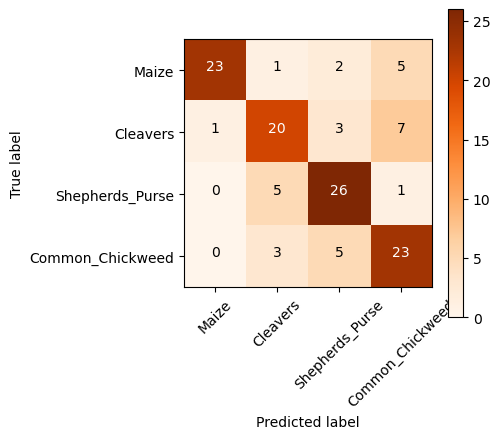

4/4 [==============================] - 0s 14ms/step
Confusion matrix on test set: 
[[23  1  5  3]
 [ 0 25  3  3]
 [ 1  3 23  4]
 [ 2  7  3 19]]


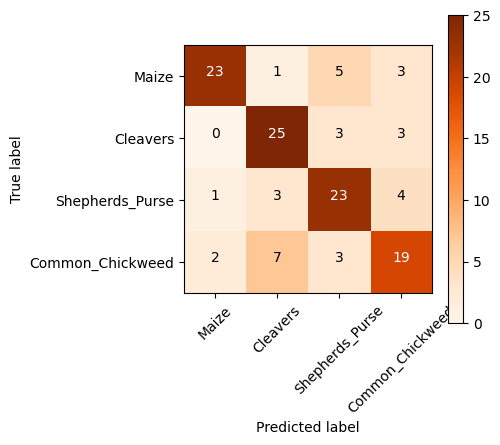

In [15]:
# Predict on the validation set
val_label_pred = vgg_model_clf.predict(val_x)
print('Confusion matrix on validation set:')
plot_conf_mx(val_label_oh,val_label_pred)


# Make predictions on the testing set
test_label_pred = vgg_model_clf.predict(test_x)
print('Confusion matrix on test set: ')
plot_conf_mx(test_label_oh,test_label_pred)

## 3.2 ResNet Classification

using all but the fully-connected layers at the top of the Keras implementation of ResNet-50; 

add layers that no more than two fully connected or convolutional layers.

In [16]:
from keras.applications import ResNet50
from keras.layers import Dense
from keras.optimizers import Adam
# Load the resnet50 model with pre-trained weights
base_model_R = ResNet50(weights='imagenet', include_top=False, input_shape=(64,64, 3))

for layer in base_model_R.layers:
    layer.trainable = False
x = base_model_R.output
x = Flatten()(x)
#x = Dense(32, activation='relu')(x)
output = Dense(4, activation='softmax')(x)
resNet_transfer = Model(inputs=base_model_R.input, outputs=output)


In [17]:
print(resNet_transfer.summary())

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 64, 64, 3)]          0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 70, 70, 3)            0         ['input_2[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 32, 32, 64)           9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 32, 32, 64)           256       ['conv1_conv[0][0]']          
 on)                                                                                        

                                                                                                  
 conv2_block3_1_conv (Conv2  (None, 16, 16, 64)           16448     ['conv2_block2_out[0][0]']    
 D)                                                                                               
                                                                                                  
 conv2_block3_1_bn (BatchNo  (None, 16, 16, 64)           256       ['conv2_block3_1_conv[0][0]'] 
 rmalization)                                                                                     
                                                                                                  
 conv2_block3_1_relu (Activ  (None, 16, 16, 64)           0         ['conv2_block3_1_bn[0][0]']   
 ation)                                                                                           
                                                                                                  
 conv2_blo

 ation)                                                                                           
                                                                                                  
 conv3_block2_3_conv (Conv2  (None, 8, 8, 512)            66048     ['conv3_block2_2_relu[0][0]'] 
 D)                                                                                               
                                                                                                  
 conv3_block2_3_bn (BatchNo  (None, 8, 8, 512)            2048      ['conv3_block2_3_conv[0][0]'] 
 rmalization)                                                                                     
                                                                                                  
 conv3_block2_add (Add)      (None, 8, 8, 512)            0         ['conv3_block1_out[0][0]',    
                                                                     'conv3_block2_3_bn[0][0]']   
          

 conv4_block1_2_conv (Conv2  (None, 4, 4, 256)            590080    ['conv4_block1_1_relu[0][0]'] 
 D)                                                                                               
                                                                                                  
 conv4_block1_2_bn (BatchNo  (None, 4, 4, 256)            1024      ['conv4_block1_2_conv[0][0]'] 
 rmalization)                                                                                     
                                                                                                  
 conv4_block1_2_relu (Activ  (None, 4, 4, 256)            0         ['conv4_block1_2_bn[0][0]']   
 ation)                                                                                           
                                                                                                  
 conv4_block1_0_conv (Conv2  (None, 4, 4, 1024)           525312    ['conv3_block4_out[0][0]']    
 D)       

                                                                                                  
 conv4_block3_out (Activati  (None, 4, 4, 1024)           0         ['conv4_block3_add[0][0]']    
 on)                                                                                              
                                                                                                  
 conv4_block4_1_conv (Conv2  (None, 4, 4, 256)            262400    ['conv4_block3_out[0][0]']    
 D)                                                                                               
                                                                                                  
 conv4_block4_1_bn (BatchNo  (None, 4, 4, 256)            1024      ['conv4_block4_1_conv[0][0]'] 
 rmalization)                                                                                     
                                                                                                  
 conv4_blo

 D)                                                                                               
                                                                                                  
 conv4_block6_3_bn (BatchNo  (None, 4, 4, 1024)           4096      ['conv4_block6_3_conv[0][0]'] 
 rmalization)                                                                                     
                                                                                                  
 conv4_block6_add (Add)      (None, 4, 4, 1024)           0         ['conv4_block5_out[0][0]',    
                                                                     'conv4_block6_3_bn[0][0]']   
                                                                                                  
 conv4_block6_out (Activati  (None, 4, 4, 1024)           0         ['conv4_block6_add[0][0]']    
 on)                                                                                              
          

 conv5_block3_1_relu (Activ  (None, 2, 2, 512)            0         ['conv5_block3_1_bn[0][0]']   
 ation)                                                                                           
                                                                                                  
 conv5_block3_2_conv (Conv2  (None, 2, 2, 512)            2359808   ['conv5_block3_1_relu[0][0]'] 
 D)                                                                                               
                                                                                                  
 conv5_block3_2_bn (BatchNo  (None, 2, 2, 512)            2048      ['conv5_block3_2_conv[0][0]'] 
 rmalization)                                                                                     
                                                                                                  
 conv5_block3_2_relu (Activ  (None, 2, 2, 512)            0         ['conv5_block3_2_bn[0][0]']   
 ation)   

train this model and show the loss accuracy during trainig and on validation set, test set:
use cross-entropy as loss and accuracy as error metric with printing the confusion matrix

In [18]:
from tensorflow.python.keras import optimizers
batchSize = 32
nEpochs = 30
#adam = tf.keras.optimizers.legacy.Adam(learning_rate = 0.001) 
resNet_transfer.compile(optimizer= "adam", loss='categorical_crossentropy', metrics=['accuracy'])  

#test_mse_resNet = TestMSE((test_x, test_label_oh))
history_resNet = resNet_transfer.fit(
                    train_x,train_label_oh,
                    batch_size=batchSize, 
                    epochs=nEpochs,  
                    validation_data=(val_x,val_label_oh),
                    verbose=1,
                    #callbacks=[test_mse_resNet]
                    )


Epoch 1/30
24/24 [==============================] - 22s 669ms/step - loss: 1.4128 - accuracy: 0.2240 - val_loss: 1.3898 - val_accuracy: 0.2560
Epoch 2/30
24/24 [==============================] - 2s 67ms/step - loss: 1.3984 - accuracy: 0.2493 - val_loss: 1.3880 - val_accuracy: 0.2640
Epoch 3/30
24/24 [==============================] - 2s 65ms/step - loss: 1.4207 - accuracy: 0.2613 - val_loss: 1.3901 - val_accuracy: 0.2640
Epoch 4/30
24/24 [==============================] - 2s 68ms/step - loss: 1.3947 - accuracy: 0.2787 - val_loss: 1.3860 - val_accuracy: 0.2640
Epoch 5/30
24/24 [==============================] - 2s 68ms/step - loss: 1.3891 - accuracy: 0.2707 - val_loss: 1.4091 - val_accuracy: 0.2720
Epoch 6/30
24/24 [==============================] - 2s 67ms/step - loss: 1.3787 - accuracy: 0.2947 - val_loss: 1.3965 - val_accuracy: 0.2400
Epoch 7/30
24/24 [==============================] - 2s 71ms/step - loss: 1.3789 - accuracy: 0.2760 - val_loss: 1.3781 - val_accuracy: 0.2880
Epoch 8/30


Evaluate the model on the validation and test set

In [19]:
# Evaluate the model on the validation and test set
loss_val, acc_val = resNet_transfer.evaluate(val_x,val_label_oh)
print(f'Validation Loss: {loss_val:.4f}, Validation Accuracy: {acc_val:.4f}')
loss_test, acc_test = resNet_transfer.evaluate(test_x,test_label_oh)
print(f'Test Loss: {loss_test:.4f}, test Accuracy: {acc_test:.4f}')


4/4 [==============================] - 0s 55ms/step - loss: 1.3975 - accuracy: 0.2720
Validation Loss: 1.3975, Validation Accuracy: 0.2720
4/4 [==============================] - 0s 57ms/step - loss: 1.4107 - accuracy: 0.2880
Test Loss: 1.4107, test Accuracy: 0.2880


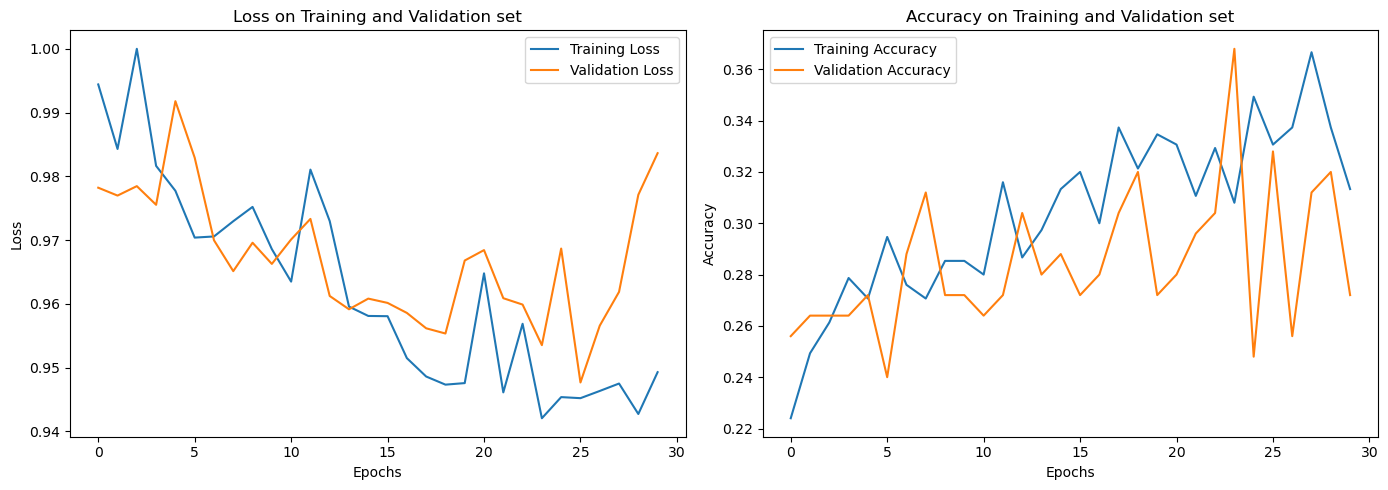

In [20]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plot_loss(nEpochs,history_resNet)
plt.subplot(1, 2, 2)
plot_acc(nEpochs,history_resNet)

4/4 [==============================] - 9s 2s/step
Confusion matrix on validation set:
[[ 0  0  1 30]
 [ 0  0  3 28]
 [ 0  0  3 29]
 [ 0  0  0 31]]


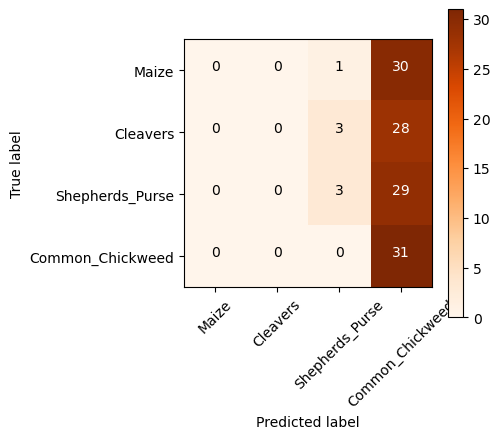

4/4 [==============================] - 0s 26ms/step
Confusion matrix on test set: 
[[ 0  0  2 30]
 [ 0  1  1 29]
 [ 0  0  8 23]
 [ 0  0  4 27]]


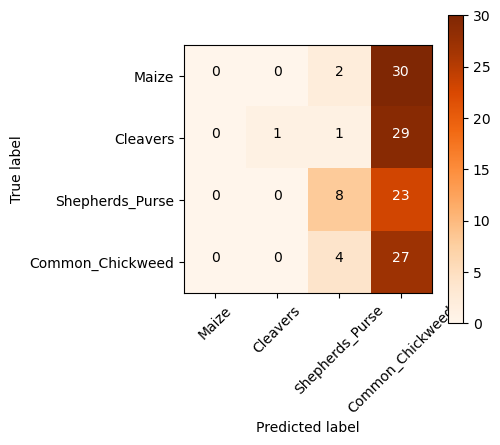

In [22]:
# Predict on the validation set
val_label_pred = resNet_transfer.predict(val_x)
print('Confusion matrix on validation set:')
plot_conf_mx(val_label_oh,val_label_pred)


# Make predictions on the testing set
test_label_pred = resNet_transfer.predict(test_x)
print('Confusion matrix on test set: ')
plot_conf_mx(test_label_oh,test_label_pred)

## 3.3 discussion

## 4.1  Regression Network based on VGG16

In [23]:
from tensorflow.keras.layers import Activation

#set non-trainable
for layer in base_model.layers:
    layer.trainable = False

# Using the first two blocks 
x = base_model.layers[6].output
x = Conv2D(64,(3,3), activation='relu')(x)  
x = MaxPooling2D(pool_size=(2, 2))(x)
x = Flatten()(x)
#x = Dense(256,activation='relu')(x) 
output_reg = Dense(2,activation = None )(x)  

vgg_model_rgs = Model(inputs=base_model.input, outputs= output_reg)

In [24]:
print(vgg_model_rgs.summary())

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 64, 64, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 64, 64, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 64, 64, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 32, 32, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 32, 32, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 32, 32, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 16, 16, 128)       0   

In [25]:
def hei_wid(dataset):
    heights = dataset["bbox"].apply(lambda x: x['height']).values
    widths = dataset['bbox'].apply(lambda x: x['width']).values
    
    bbox = np.stack((widths,heights), axis=-1)
    return bbox

output the shape of bounding box, and the first 5 of training bounding box

In [26]:
bbox_train = hei_wid(data_train)
bbox_val = hei_wid(data_val)
bbox_test = hei_wid(data_test)
print(bbox_train.shape)
print(bbox_train[:5])

(750, 2)
[[0.51685393 0.82022472]
 [0.80487805 0.46341463]
 [0.81818182 0.63636364]
 [0.62391304 0.96521739]
 [0.31845842 0.98377282]]


Compute and print MSE on the test set while training 

In [27]:
from sklearn.metrics import mean_squared_error
from tensorflow.keras.callbacks import Callback
import numpy as np

#  compute and print MSE on the test set
class TestMSE(Callback):
    def __init__(self, test_data):
        super().__init__()
        self.test_data = test_data
        self.test_mse = []

    def on_epoch_end(self, epoch, logs = {}):
        x,y = self.test_data
        mse = self.model.evaluate(x, y, verbose=0)[1]
        self.test_mse.append(mse)
        print(f"- test MSE: {mse}\n")



train this model and show the MSE during trainig as well as on validation set, test set

In [28]:
batchSize = 32
nEpochs = 30

# Compile the model
adam = tf.keras.optimizers.legacy.Adam(learning_rate=LearnRate)
vgg_model_rgs.compile(optimizer=adam, loss='mean_squared_error',metrics=['mse']) #  

test_mse_vggRGS = TestMSE((test_x,bbox_test))
history_vggRGS = vgg_model_rgs.fit(
    train_x,  # Training images
    bbox_train,  # Training labels (height and width)
    validation_data=(val_x, bbox_val),  # Validation data
    epochs=nEpochs,
    batch_size=batchSize,
    verbose=1,
    callbacks=[test_mse_vggRGS]
)



Epoch 1/30
24/24 [==============================] - ETA: 0s - loss: 63.4188 - mse: 63.4188- test MSE: 1.5320470333099365

24/24 [==============================] - 4s 111ms/step - loss: 63.4188 - mse: 63.4188 - val_loss: 1.3664 - val_mse: 1.3664
Epoch 2/30
20/24 [========================>.....] - ETA: 0s - loss: 1.0026 - mse: 1.0026- test MSE: 0.5975835919380188

24/24 [==============================] - 0s 18ms/step - loss: 0.9189 - mse: 0.9189 - val_loss: 0.5152 - val_mse: 0.5152
Epoch 3/30
22/24 [==========================>...] - ETA: 0s - loss: 0.4190 - mse: 0.4190- test MSE: 0.41298291087150574

24/24 [==============================] - 0s 18ms/step - loss: 0.4121 - mse: 0.4121 - val_loss: 0.3526 - val_mse: 0.3526
Epoch 4/30
22/24 [==========================>...] - ETA: 0s - loss: 0.3058 - mse: 0.3058- test MSE: 0.33784279227256775

24/24 [==============================] - 0s 18ms/step - loss: 0.3047 - mse: 0.3047 - val_loss: 0.2764 - val_mse: 0.2764
Epoch 5/30
21/24 [===============

make a prediction on testset and show the resluts

In [29]:
# predicton testset
pred_HW = vgg_model_rgs.predict(test_x)[:5]
print("prediction of width height on the test set:\n",pred_HW)
print("ground truth of width height on the test set:\n",bbox_test[:5])

4/4 [==============================] - 1s 154ms/step
prediction of width height on the test set:
 [[0.56034046 0.5845115 ]
 [0.91475534 0.6082564 ]
 [0.8578472  0.24062915]
 [0.65353745 0.35499457]
 [0.84943026 1.114173  ]]
ground truth of width height on the test set:
 [[0.68316832 0.96039604]
 [0.66064982 0.94223827]
 [0.95687332 0.39892183]
 [0.87401575 0.87401575]
 [0.93442623 0.54098361]]


In [30]:
def plot_mse(history,test_mse:TestMSE, ymax = None):
    plt.figure(figsize=(5,4))
    if ymax: plt.ylim(0, ymax)
    plt.plot(history.history['mse'])
    plt.plot(history.history['val_mse'])
    plt.title('MSE on train,validation,test sets')
    plt.ylabel('MSE')
    plt.xlabel('Epoch')
    if test_mse is not None:
        plt.plot(test_mse)
        plt.legend(['Train', 'Validation', 'Test'])
    else:
        plt.legend(['Train', 'Validation'])
    plt.show()

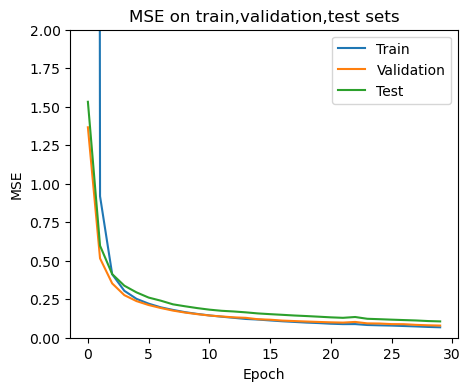

In [31]:
plot_mse(history_vggRGS, test_mse_vggRGS.test_mse, ymax = 2)    

In [32]:
from sklearn.metrics import mean_squared_error

def MSE_sets(model,x,y):
    pred = model.predict(x)
    mse = mean_squared_error(y, pred)
    return mse

In [33]:

# Calculate MSE for those dataset
mse_train_V = MSE_sets(vgg_model_rgs,train_x,bbox_train)
print("Training MSE:", mse_train_V)
mse_val_V = MSE_sets(vgg_model_rgs,val_x,bbox_val)
print("Validation MSE:", mse_val_V)
mse_test_V = MSE_sets(vgg_model_rgs,test_x,bbox_test)
print("Testing MSE:", mse_test_V)

24/24 [==============================] - 1s 26ms/step
Training MSE: 0.06610907651882438
4/4 [==============================] - 0s 14ms/step
Validation MSE: 0.07896189503248052
4/4 [==============================] - 0s 13ms/step
Testing MSE: 0.10598945312257654


## 4.2 Multi-task and other Regularization

Combine networks in Questions 3.1 and 4.1 for a multi-task regularization. 

Incorporate a second regularization method: Batch Normalization and Dropout into layers of this network.

In [43]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

#set non-trainable
for layer in base_model.layers:
    layer.trainable = False
    
# Define the Classification Model
x = base_model.layers[6].output
x = Conv2D(64,(3,3), activation='relu')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)
x = BatchNormalization()(x)  # Batch Normalization
x = Dropout(0.3)(x)
x = Flatten()(x)
output_clf = Dense(4, activation='softmax',name='class_label')(x)
output_rgs =  Dense(2, name='bounding_box')(x)

multi_model = Model(inputs= base_model.input, outputs=[output_clf, output_rgs])

# Compile the Multi-Output Model
lossWeights = {
    "class_label": 1.0,
    "bounding_box": 1.0
}
adam = tf.keras.optimizers.legacy.Adam(learning_rate=LearnRate)
multi_model.compile(  optimizer=adam,
                      loss={'class_label': 'categorical_crossentropy', 'bounding_box': 'mean_squared_error'},
                      metrics={'class_label': 'accuracy', 'bounding_box': 'mean_squared_error'},
                      loss_weights=lossWeights )

batchSize =32
nEpochs=30
# Train the Multi-Output Model
train_target = {'class_label': train_label_oh, 'bounding_box': bbox_train}
val_target = {'class_label': val_label_oh, 'bounding_box': bbox_val}
test_target = {'class_label': test_label_oh, 'bounding_box': bbox_test}
history_multi = multi_model.fit( train_x,train_target,
                            validation_data=(val_x,val_target),
                            epochs=nEpochs,
                            batch_size=batchSize,
                              verbose=1)



Epoch 1/30
24/24 [==============================] - 7s 196ms/step - loss: 3.8689 - class_label_loss: 1.4687 - bounding_box_loss: 2.4003 - class_label_accuracy: 0.4573 - bounding_box_mean_squared_error: 2.4003 - val_loss: 19.4458 - val_class_label_loss: 4.6963 - val_bounding_box_loss: 14.7494 - val_class_label_accuracy: 0.4480 - val_bounding_box_mean_squared_error: 14.7494
Epoch 2/30
24/24 [==============================] - 1s 60ms/step - loss: 2.0316 - class_label_loss: 0.6050 - bounding_box_loss: 1.4266 - class_label_accuracy: 0.7827 - bounding_box_mean_squared_error: 1.4266 - val_loss: 17.8457 - val_class_label_loss: 8.3094 - val_bounding_box_loss: 9.5363 - val_class_label_accuracy: 0.2640 - val_bounding_box_mean_squared_error: 9.5363
Epoch 3/30
24/24 [==============================] - 2s 64ms/step - loss: 1.2860 - class_label_loss: 0.4010 - bounding_box_loss: 0.8850 - class_label_accuracy: 0.8547 - bounding_box_mean_squared_error: 0.8850 - val_loss: 9.8611 - val_class_label_loss: 5.

Evaluate the model on the  validation and test data

In [44]:
def evl_multi_model(x,target):
    metrics = multi_model.evaluate(x, target, verbose=0)

    classification_loss = metrics[1]
    classification_accuracy = metrics[3]
    regression_loss = metrics[2]
    regression_mean_squared_error = metrics[4]

    # Print the metrics
    print("Classification Loss:", classification_loss)
    print("Classification Accuracy:", classification_accuracy)
    print("Regression Loss:", regression_loss)
    print("Regression Mean Squared Error:", regression_mean_squared_error)

print("validation set:")
evl_multi_model(val_x, val_target)
print("test set:")
evl_multi_model(test_x, test_target)

validation set:
Classification Loss: 0.35244858264923096
Classification Accuracy: 0.871999979019165
Regression Loss: 0.06468809396028519
Regression Mean Squared Error: 0.06468809396028519
test set:
Classification Loss: 0.4634370803833008
Classification Accuracy: 0.8399999737739563
Regression Loss: 0.0780564546585083
Regression Mean Squared Error: 0.0780564546585083


show the prediction on validation set

4/4 [==============================] - 1s 135ms/step
Confusion matrix on validation set:
[[30  0  1  0]
 [ 2 27  0  2]
 [ 3  2 27  0]
 [ 4  2  0 25]]


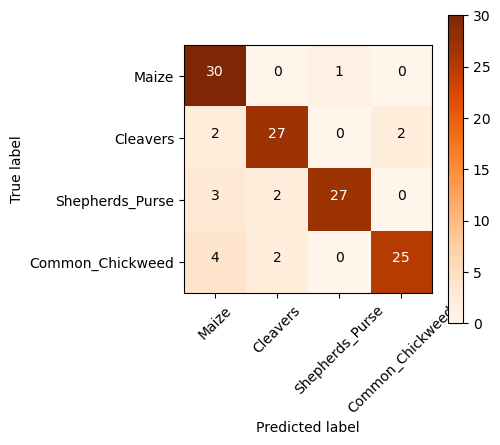

prediction of width height on the validation set:
 [[0.5620117  0.90032786]
 [1.1242977  0.60327244]
 [1.022349   0.98602134]
 [0.46063736 0.90383273]
 [1.0331132  0.5710816 ]]
ground truth of width height on the validation set:
 [[0.93333333 0.8       ]
 [0.84158416 0.44554455]
 [0.73333333 0.89333333]
 [0.71022727 0.90909091]
 [0.94052045 0.70260223]]


In [45]:
# Predict on the validation set
pred_val = multi_model.predict(val_x)
# Extract the classification and regression predictions
val_clf_pred = pred_val[0]
print('Confusion matrix on validation set:')
plot_conf_mx(val_label_oh,val_clf_pred)
val_rgs_pred = pred_val[1]
print("prediction of width height on the validation set:\n",val_rgs_pred[:5])
print("ground truth of width height on the validation set:\n",bbox_val[:5])



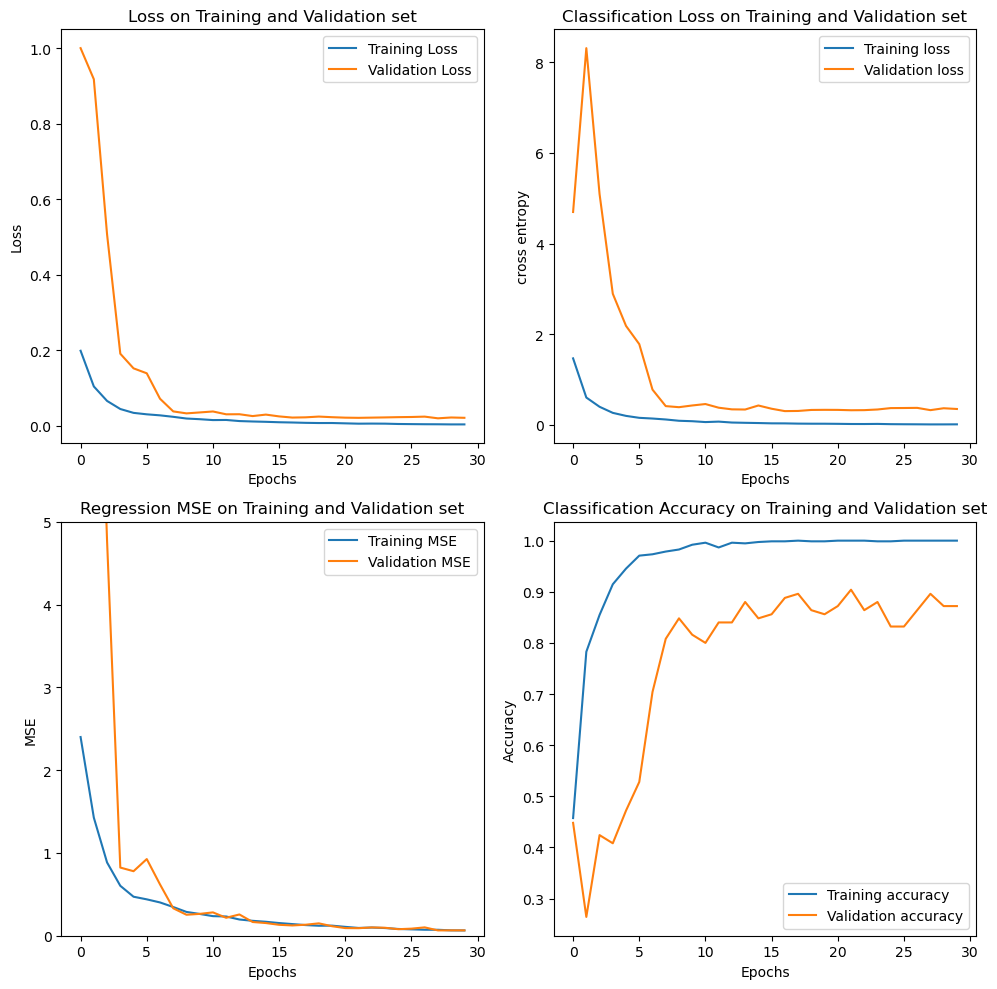

In [47]:
plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
plot_loss(nEpochs, history_multi)
plt.subplot(2, 2, 2)
plt.plot(history_multi.history['class_label_loss'], label='Training loss')
plt.plot(history_multi.history['val_class_label_loss'], label='Validation loss')
plt.title('Classification Loss on Training and Validation set')
plt.xlabel('Epochs')
plt.ylabel('cross entropy')
plt.legend()
plt.subplot(2, 2, 3)
plt.ylim(0, 5)
plt.plot(history_multi.history['bounding_box_mean_squared_error'], label='Training MSE')
plt.plot(history_multi.history['val_bounding_box_mean_squared_error'], label='Validation MSE')
plt.title('Regression MSE on Training and Validation set')
plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.legend()
plt.subplot(2, 2, 4)
plt.plot(history_multi.history['class_label_accuracy'], label='Training accuracy')
plt.plot(history_multi.history['val_class_label_accuracy'], label='Validation accuracy')
plt.title('Classification Accuracy on Training and Validation set')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

## discussion